# Step 3: Feature Extraction - YOGA Chatbot

**Chatbot Name**: YOGA (YOgyakarta Guide Assistant)

**Objective**: Transform preprocessed text into numerical vector representations using Word2Vec

**Date**: 2025-11-24

**Input**: Preprocessed text from Step 2 (1326 patterns, 92 labels)

**Feature Extraction Method**: **Word2Vec**

**Feature Extraction Steps**:
1. Load preprocessed data
2. Prepare tokenized sentences for Word2Vec
3. Train Word2Vec model
4. Create document vectors (average word vectors)
5. Label Encoding
6. **Display vector representations** (visualisasi)
7. Save feature vectors (X dan y) - **belum di-split**

**Note**: 
- **Train-test split akan dilakukan di Step 4 (Modeling)**
- Output Step 3: **X (Word2Vec vectors)** dan **y (encoded labels)** untuk semua data
- Word2Vec trained from scratch on our domain-specific data

## 1. Import Libraries

In [43]:
import pandas as pd
import numpy as np
import json
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
import os

# Gensim for Word2Vec
from gensim.models import Word2Vec
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Set random seed for reproducibility
np.random.seed(42)

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


## 2. Load Preprocessed Data

In [44]:
# Load preprocessed text from Step 2
print("=" * 80)
print("LOADING PREPROCESSED DATA")
print("=" * 80)

df = pd.read_csv('../data/preprocessed/preprocessed_text.csv', encoding='utf-8')

print(f"✓ Data loaded: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFirst 5 rows:")
print(df.head())

# Load preprocessing info
with open('../data/preprocessed/preprocessing_info.json', 'r', encoding='utf-8') as f:
    preprocess_info = json.load(f)

print(f"\n📊 Dataset Info:")
print(f"  Total patterns: {preprocess_info['total_patterns']}")
print(f"  Unique labels: {preprocess_info['unique_labels']}")
print(f"  Vocabulary size: {preprocess_info['stemmed_vocab_size']}")

LOADING PREPROCESSED DATA
✓ Data loaded: (4921, 3)

Columns: ['pattern', 'processed_text', 'label']

First 5 rows:
  pattern processed_text     label
0    halo           halo  greeting
1     hai            hai  greeting
2     hey            hey  greeting
3   hello          hello  greeting
4      hi             hi  greeting

📊 Dataset Info:
  Total patterns: 4921
  Unique labels: 88
  Vocabulary size: 302


## 3. Data Overview

In [45]:
# Check data quality
print("=" * 80)
print("DATA QUALITY CHECK")
print("=" * 80)

print(f"\nMissing values:")
print(df.isnull().sum())

print(f"\nLabel distribution (top 10):")
print(df['label'].value_counts().head(10))

print(f"\nProcessed text length statistics:")
# Handle empty or NaN values in processed_text
df['text_length'] = df['processed_text'].fillna('').apply(lambda x: len(str(x).split()) if x else 0)
print(f"  Mean: {df['text_length'].mean():.2f} words")
print(f"  Median: {df['text_length'].median():.0f} words")
print(f"  Min: {df['text_length'].min()} words")
print(f"  Max: {df['text_length'].max()} words")
print(f"  Std: {df['text_length'].std():.2f}")

DATA QUALITY CHECK

Missing values:
pattern           0
processed_text    0
label             0
dtype: int64

Label distribution (top 10):
label
greeting             60
kecamatan_ngawen     60
kecamatan_godean     60
kecamatan_imogiri    60
kecamatan_kalasan    60
kecamatan_kasihan    60
kecamatan_minggir    60
pagi                 60
kecamatan_pakem      60
kecamatan_gamping    60
Name: count, dtype: int64

Processed text length statistics:
  Mean: 3.87 words
  Median: 3 words
  Min: 1 words
  Max: 10 words
  Std: 1.96


## 4. Prepare Tokenized Sentences for Word2Vec

In [46]:
# Prepare sentences (list of lists of words) for Word2Vec
print("=" * 80)
print("PREPARING TOKENIZED SENTENCES")
print("=" * 80)

# Convert processed_text to list of word lists
sentences = []
for text in df['processed_text']:
    if pd.notna(text) and text.strip():
        words = str(text).split()
        sentences.append(words)
    else:
        sentences.append([])  # Empty list for empty text

print(f"✓ Prepared {len(sentences)} sentences")

# Calculate vocabulary
all_words = [word for sent in sentences for word in sent]
vocab = set(all_words)

print(f"\nVocabulary statistics:")
print(f"  Total words (with repetition): {len(all_words)}")
print(f"  Unique words: {len(vocab)}")

# Sentence length statistics
sent_lengths = [len(sent) for sent in sentences]
print(f"\nSentence length statistics:")
print(f"  Mean: {np.mean(sent_lengths):.2f} words")
print(f"  Min: {np.min(sent_lengths)} words")
print(f"  Max: {np.max(sent_lengths)} words")

print(f"\nExample sentences (first 5):")
for i in range(5):
    print(f"\n{i+1}. Original: {df['pattern'].iloc[i]}")
    print(f"   Processed: {df['processed_text'].iloc[i]}")
    print(f"   Tokenized: {sentences[i]}")

PREPARING TOKENIZED SENTENCES
✓ Prepared 4921 sentences

Vocabulary statistics:
  Total words (with repetition): 19026
  Unique words: 302

Sentence length statistics:
  Mean: 3.87 words
  Min: 1 words
  Max: 10 words

Example sentences (first 5):

1. Original: halo
   Processed: halo
   Tokenized: ['halo']

2. Original: hai
   Processed: hai
   Tokenized: ['hai']

3. Original: hey
   Processed: hey
   Tokenized: ['hey']

4. Original: hello
   Processed: hello
   Tokenized: ['hello']

5. Original: hi
   Processed: hi
   Tokenized: ['hi']


## 5. Train Word2Vec Model

In [47]:
# Train Word2Vec model
print("=" * 80)
print("TRAINING WORD2VEC MODEL")
print("=" * 80)

# Word2Vec hyperparameters
vector_size = 100      # Dimensionality of word vectors
window = 5             # Context window size
min_count = 1          # Minimum word frequency (1 = keep all words)
workers = 4            # Number of threads
sg = 0                 # 0 = CBOW, 1 = Skip-gram
epochs = 100           # Training epochs

print(f"\nWord2Vec hyperparameters:")
print(f"  vector_size: {vector_size}")
print(f"  window: {window}")
print(f"  min_count: {min_count}")
print(f"  algorithm: {'CBOW' if sg == 0 else 'Skip-gram'}")
print(f"  epochs: {epochs}")

# Train Word2Vec
print(f"\n⏳ Training Word2Vec model...")
w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=vector_size,
    window=window,
    min_count=min_count,
    workers=workers,
    sg=sg,
    epochs=epochs,
    seed=42
)

print(f"\n✓ Word2Vec model trained successfully!")
print(f"\nModel vocabulary size: {len(w2v_model.wv)}")
print(f"Vector dimensions: {w2v_model.wv.vector_size}")

TRAINING WORD2VEC MODEL

Word2Vec hyperparameters:
  vector_size: 100
  window: 5
  min_count: 1
  algorithm: CBOW
  epochs: 100

⏳ Training Word2Vec model...

✓ Word2Vec model trained successfully!

Model vocabulary size: 302
Vector dimensions: 100


## 6. Explore Word Embeddings

In [48]:
# Explore word embeddings
print("=" * 80)
print("WORD EMBEDDINGS EXPLORATION")
print("=" * 80)

# Sample word vectors
sample_words = ['wisata', 'yoga', 'sleman', 'bantul', 'prambanan', 'pantai']

print(f"\nSample word vectors:")
for word in sample_words:
    if word in w2v_model.wv:
        vector = w2v_model.wv[word]
        print(f"\n'{word}':")
        print(f"  Vector (first 10 dims): {vector[:10]}")
        print(f"  Vector length: {len(vector)}")
        
        # Find similar words
        try:
            similar = w2v_model.wv.most_similar(word, topn=3)
            print(f"  Similar words: {similar}")
        except:
            print(f"  Similar words: Not enough data")
    else:
        print(f"\n'{word}': Not in vocabulary")

WORD EMBEDDINGS EXPLORATION

Sample word vectors:

'wisata':
  Vector (first 10 dims): [ 1.387191   -1.8094985   0.5856201  -0.9045302   1.0791322  -0.9666747
  0.63414    -0.8043571   0.10671312 -0.26056948]
  Vector length: 100
  Similar words: [('destinasi', 0.5868716239929199), ('pleret', 0.44688570499420166), ('pandak', 0.4462321996688843)]

'yoga':
  Vector (first 10 dims): [-1.0519746e-01  2.9019159e-01  3.6674267e-01 -4.3918663e-01
  8.0700755e-01  1.2876149e+00 -7.0287228e-01  7.8565019e-01
 -2.1409307e-01  7.9224835e-04]
  Vector length: 100
  Similar words: [('rekomen', 0.5761546492576599), ('gud', 0.5695884823799133), ('ok', 0.49123015999794006)]

'sleman':
  Vector (first 10 dims): [ 0.28057805 -1.3593903  -0.33249295  0.04655304  0.53694683 -0.28064543
 -0.8532788  -0.74136883  0.21742533  0.32883093]
  Vector length: 100
  Similar words: [('bantul', 0.8625350594520569), ('kulonprogo', 0.7475875020027161), ('tempel', 0.7455909848213196)]

'bantul':
  Vector (first 10 dims

## 7. Create Sequence Vectors for LSTM

In [49]:
# Create sequence of word vectors for LSTM
print("=" * 80)
print("CREATE SEQUENCE VECTORS FOR LSTM")
print("=" * 80)

# Determine max sequence length
sent_lengths = [len(sent) for sent in sentences]
max_length = int(np.percentile(sent_lengths, 95))  # 95th percentile

print(f"Sequence length statistics:")
print(f"  Mean: {np.mean(sent_lengths):.2f}")
print(f"  Max: {np.max(sent_lengths)}")
print(f"  95th percentile: {max_length}")
print(f"\n✓ Selected max_length: {max_length}")

# Create padded sequence vectors
def get_sequence_vectors(tokens, model, max_len, vec_size):
    """
    Convert tokens to sequence of word vectors with padding.
    Shape: (max_len, vec_size)
    """
    seq_vectors = []
    for word in tokens[:max_len]:  # Truncate if too long
        if word in model.wv:
            seq_vectors.append(model.wv[word])
        else:
            seq_vectors.append(np.zeros(vec_size))  # OOV
    
    # Pad with zeros if too short
    while len(seq_vectors) < max_len:
        seq_vectors.append(np.zeros(vec_size))
    
    return np.array(seq_vectors)

# Create sequence features for all documents
print(f"\n⏳ Creating sequence vectors...")
X = np.array([get_sequence_vectors(sent, w2v_model, max_length, vector_size) for sent in sentences])

print(f"\n✓ Sequence vectors created")
print(f"\nShape of X (sequence vectors): {X.shape}")
print(f"  Number of samples: {X.shape[0]}")
print(f"  Sequence length: {X.shape[1]}")
print(f"  Vector dimension: {X.shape[2]}")
print(f"\nX is a 3D tensor of shape ({X.shape[0]}, {X.shape[1]}, {X.shape[2]})")
print(f"  Axis 0 = samples")
print(f"  Axis 1 = time steps (words in sequence)")
print(f"  Axis 2 = word vector dimensions")
print(f"  Values = Word2Vec embeddings (floats)")
print(f"\n✅ Ready for LSTM input!")

CREATE SEQUENCE VECTORS FOR LSTM
Sequence length statistics:
  Mean: 3.87
  Max: 10
  95th percentile: 8

✓ Selected max_length: 8

⏳ Creating sequence vectors...

✓ Sequence vectors created

Shape of X (sequence vectors): (4921, 8, 100)
  Number of samples: 4921
  Sequence length: 8
  Vector dimension: 100

X is a 3D tensor of shape (4921, 8, 100)
  Axis 0 = samples
  Axis 1 = time steps (words in sequence)
  Axis 2 = word vector dimensions
  Values = Word2Vec embeddings (floats)

✅ Ready for LSTM input!


## 8. Label Encoding

In [50]:
# Encode labels to integers
print("=" * 80)
print("LABEL ENCODING - CREATE LABEL VECTORS (y)")
print("=" * 80)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['label'])

print(f"✓ Label vectors created")
print(f"\nShape of y (label vectors): {y.shape}")
print(f"  Number of labels: {y.shape[0]}")
print(f"  Number of classes: {len(label_encoder.classes_)}")
print(f"\ny is a 1D array of shape ({y.shape[0]},)")
print(f"  Each value = encoded label (integer from 0 to {len(label_encoder.classes_)-1})")

print(f"\nFirst 10 classes:")
for i, label in enumerate(label_encoder.classes_[:10]):
    print(f"  {i:2d}. {label}")

print(f"\nExample encodings (first 10):")
for i in range(10):
    print(f"  {df['label'].iloc[i]:30s} → {y[i]:2d}")

LABEL ENCODING - CREATE LABEL VECTORS (y)
✓ Label vectors created

Shape of y (label vectors): (4921,)
  Number of labels: 4921
  Number of classes: 88

y is a 1D array of shape (4921,)
  Each value = encoded label (integer from 0 to 87)

First 10 classes:
   0. goodbye
   1. greeting
   2. kabupaten_bantul
   3. kabupaten_gunungkidul
   4. kabupaten_kulonprogo
   5. kabupaten_sleman
   6. kecamatan_bambanglipuro
   7. kecamatan_banguntapan
   8. kecamatan_berbah
   9. kecamatan_cangkringan

Example encodings (first 10):
  greeting                       →  1
  greeting                       →  1
  greeting                       →  1
  greeting                       →  1
  greeting                       →  1
  greeting                       →  1
  greeting                       →  1
  greeting                       →  1
  greeting                       →  1
  greeting                       →  1


## 9. Display Feature Vectors (Visualisasi)

In [51]:
# Display sequence vectors
print("=" * 80)
print("SEQUENCE VECTORS DISPLAY")
print("=" * 80)

print(f"\nShowing first 3 samples:")
print(f"\nSequence Vector X[0] (shape: {X[0].shape}):")
print(f"First 3 time steps, first 10 dimensions:")
print(X[0][:3, :10])

print(f"\nLabel Vector y (first 10 values):")
print(y[:10])

print(f"\n" + "=" * 80)
print("DETAILED EXAMPLE (Sample 0)")
print("=" * 80)
print(f"\nOriginal text: {df['pattern'].iloc[0]}")
print(f"Processed text: {df['processed_text'].iloc[0]}")
print(f"Tokenized: {sentences[0]}")
print(f"Sequence length: {len(sentences[0])} words")

print(f"\nSequence vector X[0]:")
print(f"  Shape: {X[0].shape}")
print(f"  Non-zero time steps: {np.sum(np.any(X[0] != 0, axis=1))}")
print(f"  Zero-padded time steps: {np.sum(np.all(X[0] == 0, axis=1))}")

print(f"\nFirst word '{sentences[0][0]}' vector (10 dims):")
print(X[0][0][:10])

print(f"\nLabel: {df['label'].iloc[0]}")
print(f"Encoded label y[0]: {y[0]}")

SEQUENCE VECTORS DISPLAY

Showing first 3 samples:

Sequence Vector X[0] (shape: (8, 100)):
First 3 time steps, first 10 dimensions:
[[ 0.9804495   0.56923985  0.023566   -0.05390053 -0.50362599  0.50469333
  -0.03371766  0.60395223 -0.19677646 -0.04111572]
 [ 0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.        ]]

Label Vector y (first 10 values):
[1 1 1 1 1 1 1 1 1 1]

DETAILED EXAMPLE (Sample 0)

Original text: halo
Processed text: halo
Tokenized: ['halo']
Sequence length: 1 words

Sequence vector X[0]:
  Shape: (8, 100)
  Non-zero time steps: 1
  Zero-padded time steps: 7

First word 'halo' vector (10 dims):
[ 0.9804495   0.56923985  0.023566   -0.05390053 -0.50362599  0.50469333
 -0.03371766  0.60395223 -0.19677646 -0.04111572]

Label: greeting
Encoded label y[0]: 1


## 10. Visualize Sequence Matrix

SEQUENCE MATRIX VISUALIZATION


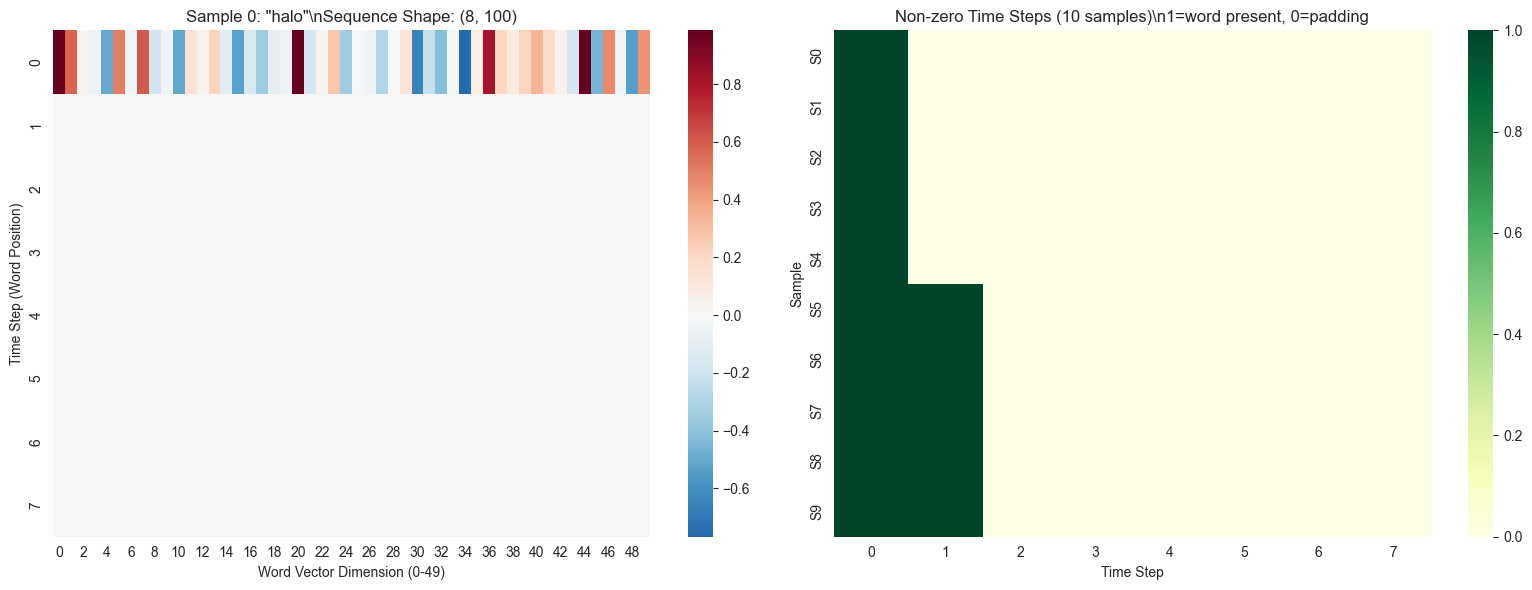


💡 Interpretation:
  Left: Each row = one word vector (100 dims shown: 0-49)
  Right: Shows which time steps have words vs padding
  Green = word present, Dark = zero padding


In [52]:
# Visualize sequence matrix
print("=" * 80)
print("SEQUENCE MATRIX VISUALIZATION")
print("=" * 80)

# Show sequence structure for first 10 samples
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap of first sample (all time steps, first 50 dims)
sns.heatmap(X[0][:, :50], cmap='RdBu_r', center=0, ax=ax1, cbar=True)
ax1.set_xlabel('Word Vector Dimension (0-49)')
ax1.set_ylabel('Time Step (Word Position)')
ax1.set_title(f'Sample 0: "{df["pattern"].iloc[0]}"\\nSequence Shape: {X[0].shape}')

# Heatmap showing which time steps are non-zero (10 samples)
mask = np.any(X[:10] != 0, axis=2).astype(int)
sns.heatmap(mask, cmap='YlGn', cbar=True, ax=ax2, 
            yticklabels=[f'S{i}' for i in range(10)])
ax2.set_xlabel('Time Step')
ax2.set_ylabel('Sample')
ax2.set_title('Non-zero Time Steps (10 samples)\\n1=word present, 0=padding')

plt.tight_layout()
plt.show()

print("\n💡 Interpretation:")
print("  Left: Each row = one word vector (100 dims shown: 0-49)")
print("  Right: Shows which time steps have words vs padding")
print("  Green = word present, Dark = zero padding")

## 11. Vector Statistics

SEQUENCE STATISTICS

Sequence tensor (X) statistics:
  Shape: (4921, 8, 100)
  Min value: -4.0467
  Max value: 3.2919
  Mean value: -0.0052
  Std value: 0.4756

Zero sequences (empty documents): 0 / 4921

Padding statistics:
  Mean non-zero time steps: 3.85
  Min non-zero time steps: 1
  Max non-zero time steps: 8


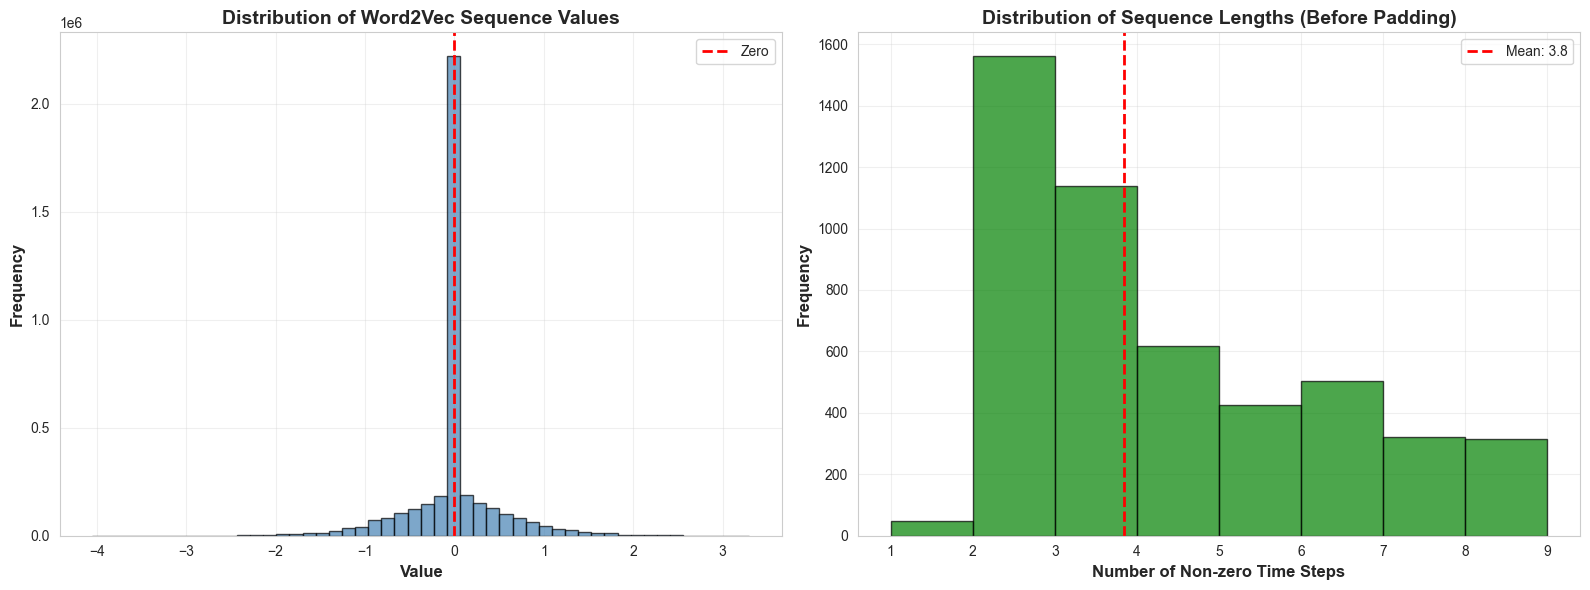

In [53]:
# Analyze sequence statistics
print("=" * 80)
print("SEQUENCE STATISTICS")
print("=" * 80)

print(f"\nSequence tensor (X) statistics:")
print(f"  Shape: {X.shape}")
print(f"  Min value: {X.min():.4f}")
print(f"  Max value: {X.max():.4f}")
print(f"  Mean value: {X.mean():.4f}")
print(f"  Std value: {X.std():.4f}")

# Check for zero sequences (empty documents)
zero_sequences = np.sum(np.all(X == 0, axis=(1, 2)))
print(f"\nZero sequences (empty documents): {zero_sequences} / {len(X)}")

# Check padding statistics
non_zero_steps = np.sum(np.any(X != 0, axis=2), axis=1)
print(f"\nPadding statistics:")
print(f"  Mean non-zero time steps: {non_zero_steps.mean():.2f}")
print(f"  Min non-zero time steps: {non_zero_steps.min()}")
print(f"  Max non-zero time steps: {non_zero_steps.max()}")

# Visualize distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Histogram of all values
ax1.hist(X.flatten(), bins=50, color='steelblue', alpha=0.7, edgecolor='black')
ax1.axvline(0, color='red', linestyle='--', linewidth=2, label='Zero')
ax1.set_xlabel('Value', fontsize=12, fontweight='bold')
ax1.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax1.set_title('Distribution of Word2Vec Sequence Values', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

# Distribution of non-zero time steps per sample
ax2.hist(non_zero_steps, bins=range(int(non_zero_steps.min()), int(non_zero_steps.max())+2), 
         color='green', alpha=0.7, edgecolor='black')
ax2.axvline(non_zero_steps.mean(), color='red', linestyle='--', linewidth=2,
            label=f'Mean: {non_zero_steps.mean():.1f}')
ax2.set_xlabel('Number of Non-zero Time Steps', fontsize=12, fontweight='bold')
ax2.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax2.set_title('Distribution of Sequence Lengths (Before Padding)', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Label Distribution Visualization

LABEL DISTRIBUTION VISUALIZATION


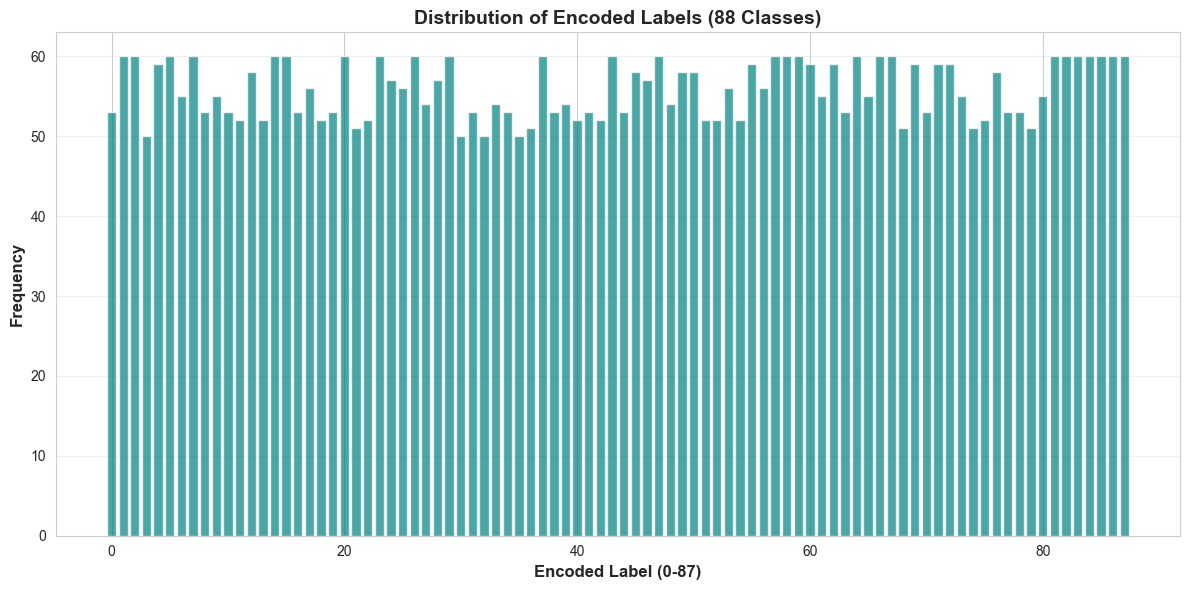


Label statistics:
  Total samples: 4921
  Number of classes: 88
  Min samples per class: 50
  Max samples per class: 60
  Mean samples per class: 55.92


In [54]:
# Visualize label distribution
print("=" * 80)
print("LABEL DISTRIBUTION VISUALIZATION")
print("=" * 80)

fig, ax = plt.subplots(figsize=(12, 6))

label_counts = pd.Series(y).value_counts().sort_index()
ax.bar(range(len(label_counts)), label_counts.values, color='teal', alpha=0.7)
ax.set_xlabel('Encoded Label (0-{})'.format(len(label_encoder.classes_)-1), 
              fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax.set_title('Distribution of Encoded Labels ({} Classes)'.format(len(label_encoder.classes_)), 
             fontsize=14, fontweight='bold')
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print(f"\nLabel statistics:")
print(f"  Total samples: {len(y)}")
print(f"  Number of classes: {len(label_encoder.classes_)}")
print(f"  Min samples per class: {label_counts.min()}")
print(f"  Max samples per class: {label_counts.max()}")
print(f"  Mean samples per class: {label_counts.mean():.2f}")

## 13. Save Feature Extraction Outputs

In [55]:
# Save Word2Vec model and sequence vectors
print("=" * 80)
print("SAVING FEATURE EXTRACTION OUTPUTS")
print("=" * 80)

output_dir = '../data/features'
os.makedirs(output_dir, exist_ok=True)

# Save X dan y (full dataset, belum split)
np.save(f'{output_dir}/X.npy', X)
np.save(f'{output_dir}/y.npy', y)

print(f"✓ Saved: X.npy (shape: {X.shape})")
print(f"✓ Saved: y.npy (shape: {y.shape})")

# Save Word2Vec model
w2v_model.save(f'{output_dir}/word2vec.model')
print(f"✓ Saved: word2vec.model")

# Save label encoder
with open(f'{output_dir}/label_encoder.pickle', 'wb') as f:
    pickle.dump(label_encoder, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"✓ Saved: label_encoder.pickle")

# Calculate zero vectors
zero_sequences = np.sum(np.all(X == 0, axis=(1, 2)))

# Save feature extraction info
feature_info = {
    'method': 'Word2Vec Sequences',
    'vector_size': vector_size,
    'window': window,
    'min_count': min_count,
    'algorithm': 'CBOW' if sg == 0 else 'Skip-gram',
    'epochs': epochs,
    'vocab_size': len(w2v_model.wv),
    'max_length': max_length,
    'num_classes': len(label_encoder.classes_),
    'total_samples': int(len(X)),
    'feature_vector_shape': list(X.shape),
    'label_vector_shape': list(y.shape),
    'zero_sequences': int(zero_sequences),
    'class_names': label_encoder.classes_.tolist(),
    'vector_stats': {
        'min': float(X.min()),
        'max': float(X.max()),
        'mean': float(X.mean()),
        'std': float(X.std())
    },
    'note': 'Sequence vectors for LSTM. Train-test split akan dilakukan di Step 4 (LSTM Modeling)'
}

with open(f'{output_dir}/feature_extraction_info.json', 'w', encoding='utf-8') as f:
    json.dump(feature_info, f, indent=2, ensure_ascii=False)

print(f"✓ Saved: feature_extraction_info.json")

print("\n" + "=" * 80)
print("ALL FILES SAVED SUCCESSFULLY")
print("=" * 80)

print(f"\nSaved files in: {output_dir}/")
print(f"  - X.npy (Word2Vec sequence vectors - belum split)")
print(f"  - y.npy (label vectors - belum split)")
print(f"  - word2vec.model (trained Word2Vec model)")
print(f"  - label_encoder.pickle")
print(f"  - feature_extraction_info.json")

SAVING FEATURE EXTRACTION OUTPUTS
✓ Saved: X.npy (shape: (4921, 8, 100))
✓ Saved: y.npy (shape: (4921,))
✓ Saved: word2vec.model
✓ Saved: label_encoder.pickle
✓ Saved: feature_extraction_info.json

ALL FILES SAVED SUCCESSFULLY

Saved files in: ../data/features/
  - X.npy (Word2Vec sequence vectors - belum split)
  - y.npy (label vectors - belum split)
  - word2vec.model (trained Word2Vec model)
  - label_encoder.pickle
  - feature_extraction_info.json


## 14. Summary

In [56]:
print("=" * 80)
print("FEATURE EXTRACTION SUMMARY - YOGA CHATBOT")
print("=" * 80)

print("\n📊 Input Data:")
print(f"  Total patterns: {len(df)}")
print(f"  Unique labels: {len(label_encoder.classes_)}")
print(f"  Source: preprocessed_text.csv (Step 2)")

print("\n🔄 Feature Extraction Method: Word2Vec Sequences")
print(f"  Algorithm: {'CBOW' if sg == 0 else 'Skip-gram'}")
print(f"  Vector size: {vector_size}")
print(f"  Window size: {window}")
print(f"  Min count: {min_count}")
print(f"  Epochs: {epochs}")
print(f"  Vocabulary size: {len(w2v_model.wv)} words")
print(f"  Max sequence length: {max_length}")

print("\n🔄 Feature Extraction Steps Completed:")
print("  1. ✓ Tokenized sentences preparation")
print("  2. ✓ Word2Vec model training")
print("  3. ✓ Sequence vector creation (with padding)")
print("  4. ✓ Label encoding")
print("  5. ✓ Vector visualization")

print("\n🔢 Output Sequences:")
print(f"  X (features): {X.shape}")
print(f"    - {X.shape[0]} samples")
print(f"    - {X.shape[1]} time steps (max_length)")
print(f"    - {X.shape[2]} dimensions (Word2Vec vector size)")
print(f"    - Values: continuous floats (Word2Vec embeddings)")
print(f"    - Range: [{X.min():.4f}, {X.max():.4f}]")
print(f"  y (labels): {y.shape}")
print(f"    - {y.shape[0]} labels")
print(f"    - Values: 0 to {len(label_encoder.classes_)-1}")

print("\n⚠️  IMPORTANT:")
print("  - Data BELUM di-split (train-test)")
print("  - Train-test split akan dilakukan di Step 4 (LSTM Modeling)")
print("  - Output: X.npy dan y.npy berisi SEMUA data")
print(f"  - Method: Word2Vec Sequences (for LSTM)")
print(f"  - X is 3D tensor: (samples, time_steps, features)")

print("\n💾 Saved Files:")
print(f"  - X.npy: Sequence vectors {X.shape}")
print(f"  - y.npy: Label vectors {y.shape}")
print(f"  - word2vec.model: Trained Word2Vec model")
print(f"  - label_encoder.pickle: Label encoder")
print(f"  - feature_extraction_info.json: Metadata")

print("\n✅ Next Steps (Step 4 - LSTM Modeling):")
print("  1. Load X.npy dan y.npy")
print("  2. Train-test split (stratified, 80/20)")
print("  3. Build LSTM model:")
print(f"      - Input: ({X.shape[1]}, {X.shape[2]}) = (time_steps, features)")
print(f"      - LSTM layers")
print(f"      - Dense layer (softmax, {len(label_encoder.classes_)} classes)")
print("  4. Compile and train")
print("  5. Evaluate on test set")

print("\n" + "=" * 80)
print("✓ FEATURE EXTRACTION COMPLETE - Ready for LSTM")
print("=" * 80)

FEATURE EXTRACTION SUMMARY - YOGA CHATBOT

📊 Input Data:
  Total patterns: 4921
  Unique labels: 88
  Source: preprocessed_text.csv (Step 2)

🔄 Feature Extraction Method: Word2Vec Sequences
  Algorithm: CBOW
  Vector size: 100
  Window size: 5
  Min count: 1
  Epochs: 100
  Vocabulary size: 302 words
  Max sequence length: 8

🔄 Feature Extraction Steps Completed:
  1. ✓ Tokenized sentences preparation
  2. ✓ Word2Vec model training
  3. ✓ Sequence vector creation (with padding)
  4. ✓ Label encoding
  5. ✓ Vector visualization

🔢 Output Sequences:
  X (features): (4921, 8, 100)
    - 4921 samples
    - 8 time steps (max_length)
    - 100 dimensions (Word2Vec vector size)
    - Values: continuous floats (Word2Vec embeddings)
    - Range: [-4.0467, 3.2919]
  y (labels): (4921,)
    - 4921 labels
    - Values: 0 to 87

⚠️  IMPORTANT:
  - Data BELUM di-split (train-test)
  - Train-test split akan dilakukan di Step 4 (LSTM Modeling)
  - Output: X.npy dan y.npy berisi SEMUA data
  - Method: 